# 4. Clustering Analysis
A. Implement K-Means clustering on Iris.csv dataset. Determine the number of clusters
using the elbow method.<br>
Dataset Link: https://www.kaggle.com/datasets/uciml/iris

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [3]:
# 1. LOAD IRIS DATASET
df = pd.read_csv("Iris.csv")
print(df.head())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [4]:
# 2. SELECT FEATURES
X = df.drop(columns=["Id", "Species"], errors="ignore")

# 3. STANDARDIZE DATA
X = StandardScaler().fit_transform(X)


In [5]:
# 4. ELBOW METHOD
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

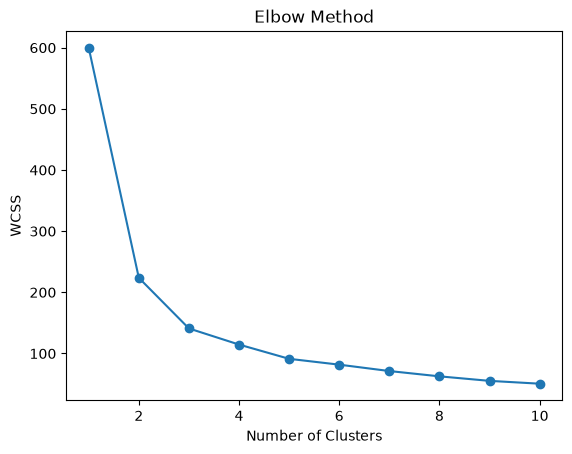

In [6]:
# 5. PLOT ELBOW GRAPH
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [10]:
# 6. APPLY K-MEANS CLUSTERING
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X)

print("\nCluster Results:")
print(df[["Cluster"]].head(10))
print("\nCluster Counts:")
print(df["Cluster"].value_counts())


Cluster Results:
   Cluster
0        1
1        1
2        1
3        1
4        1
5        1
6        1
7        1
8        1
9        1

Cluster Counts:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


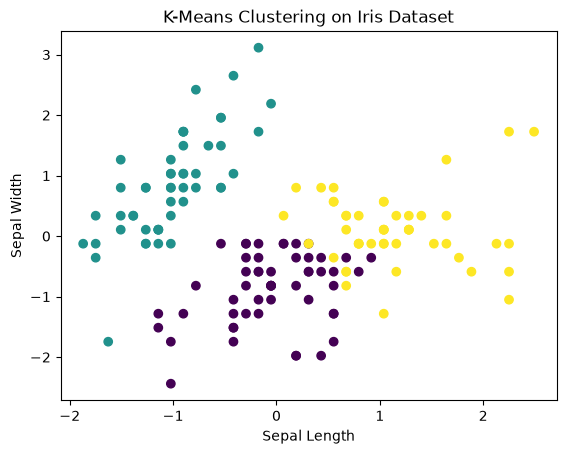

In [11]:
# 7. VISUALIZE CLUSTERS
plt.scatter(X[:, 0], X[:, 1], c=df["Cluster"], cmap="viridis")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("K-Means Clustering on Iris Dataset")
plt.show()